<a href="https://colab.research.google.com/github/cpython-projects/da_27_07_2026/blob/main/lesson_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Візуалізація даних

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/cpython-projects/python_da_17_03_26/refs/heads/main/kc_house_data.csv')
df['date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S')
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,2015-02-25,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,2014-12-09,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2015-02-18,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503


## Що таке візуалізація?

**Візуалізація даних** — це перетворення чисел у графіки. Це допомагає:

* Побачити тренди, зв’язки, аномалії;
* Краще пояснити дані замовнику чи колезі;
* Пояснити аналітику не-технічній аудиторії.
* Виявити помилки у даних;
* Підготувати звіти чи презентації.

> **Поганий графік гірше відсутності графіка.**

## На що звертати увагу

1. **Шкала (scale)**: чи є змінна кількісною, порядковою чи категоріальною.
2. **Вибір типу графіка**: scatter, bar, box, histogram — мають різні цілі.
3. **Агрегація**: barplot по середньому ≠ медіані.
4. **Пропуски та викиди**: не всі графіки "прощають" `NaN`.
5. **Маніпуляція масштабом**: неправильна шкала осі Y може спотворити висновки.
6. **Колір, форма, розмір**: візуальна увага зосереджується на яскравому — це впливає на інтерпретацію.

## Базові принципи якісної візуалізації:

| Принцип               | Пояснення                                                  |
| --------------------- | ---------------------------------------------------------- |
| 1. 📐 Адекватна шкала | Не змінюйте шкали так, щоб спотворити дані.                |
| 2. 🎯 Простота        | Один графік — одна ідея. Уникайте перенавантаження.        |
| 3. 🧩 Пояснення       | Підписи осей, легенди, заголовки — обов’язкові.            |
| 4. 🎨 Колір з сенсом  | Використовуйте колір, тільки якщо він щось означає.        |
| 5. ⚠️ Контекст        | Без осі, без одиниць виміру — це не графік, а маніпуляція. |

## Як графіки можуть обманювати?

**Приклад 1: Обрізана вісь Y**

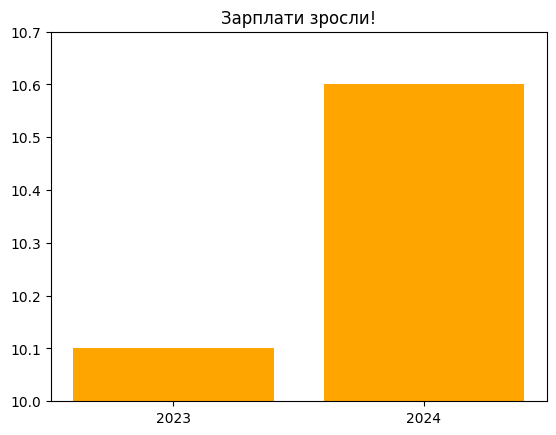

In [3]:
plt.bar(['2023', '2024'], [10.1, 10.6], color='orange')
plt.ylim(10, 10.7)
plt.title("Зарплати зросли!")
plt.show()

> Виглядає, наче зарплата підскочила вдвічі, хоча зростання — лише 5%.

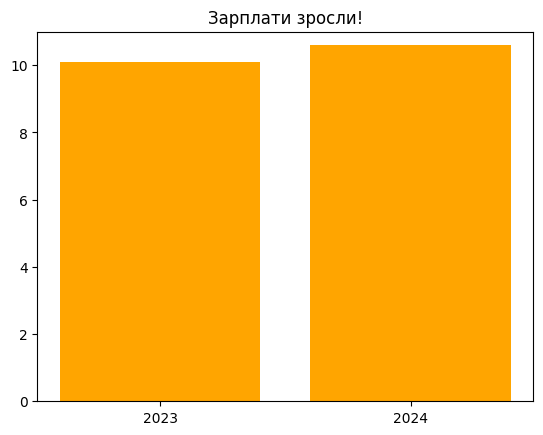

In [4]:
plt.bar(['2023', '2024'], [10.1, 10.6], color='orange')
plt.ylim(0, 11)
plt.title("Зарплати зросли!")
plt.show()

**Приклад 2: Зміна масштабу X/Y**

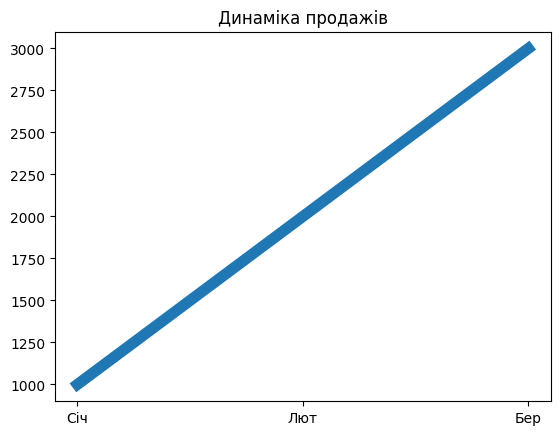

In [5]:
plt.plot([1, 2, 3], [1000, 2000, 3000], label="Продажі", linewidth=8)
plt.xticks([1, 2, 3], ['Січ', 'Лют', 'Бер'])
plt.title("Динаміка продажів")
plt.show()

> Лінія крута, бо товста лінія й "стиснутий" графік візуально підкреслюють зміну, навіть якщо вона рівно лінійна й нічим не вражає.

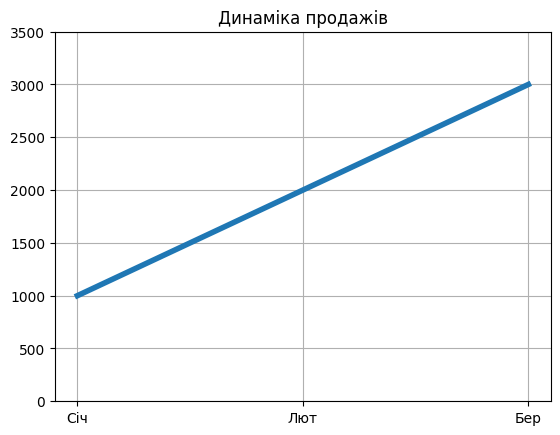

In [6]:
plt.plot([1, 2, 3], [1000, 2000, 3000], label="Продажі", linewidth=4)
plt.xticks([1, 2, 3], ['Січ', 'Лют', 'Бер'])
plt.ylim(0, 3500)
plt.title("Динаміка продажів")
plt.grid(True)
plt.show()

**Приклад 3: Друга вісь Y (secondary Y-axis)**

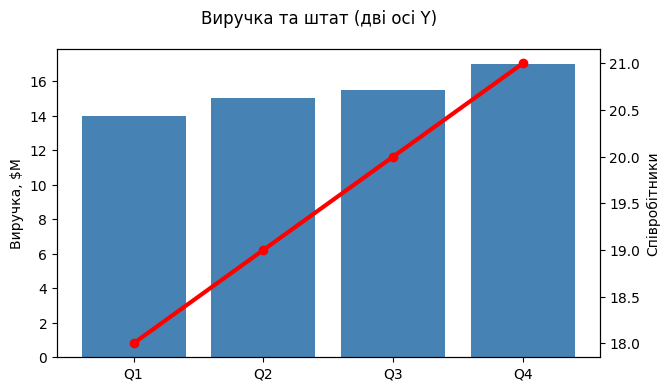

In [7]:
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
revenue = [14, 15, 15.5, 17]       # $M
employees = [18, 19, 20, 21]       # кількість людей

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(quarters, revenue, color='steelblue', label='Виручка, $M')
ax1.set_ylabel('Виручка, $M')

ax2 = ax1.twinx()
ax2.plot(quarters, employees, color='red', marker='o', linewidth=3, label='Кількість співробітників')
ax2.set_ylabel('Співробітники')

fig.suptitle("Виручка та штат (дві осі Y)")
plt.show()

### 🔴 Чому графік неефективний

* Дві шкали зліва і справа змушують постійно звіряти, яка лінія/бар до якої осі відноситься.
* Обидві шкали підібрані (діапазон) так, що лінія й бари ростуть "синхронно" — це візуально намякує на зв'язок між виручкою і штатом, якого в даних може й не бути.
* Легко створити ілюзію кореляції просто підібравши масштаб кожної осі.

### 🟢 Кращий варіант

**Два окремі графіки одна під одним зі спільною віссю X**, або підписи значень прямо на точках/барах замість другої осі.

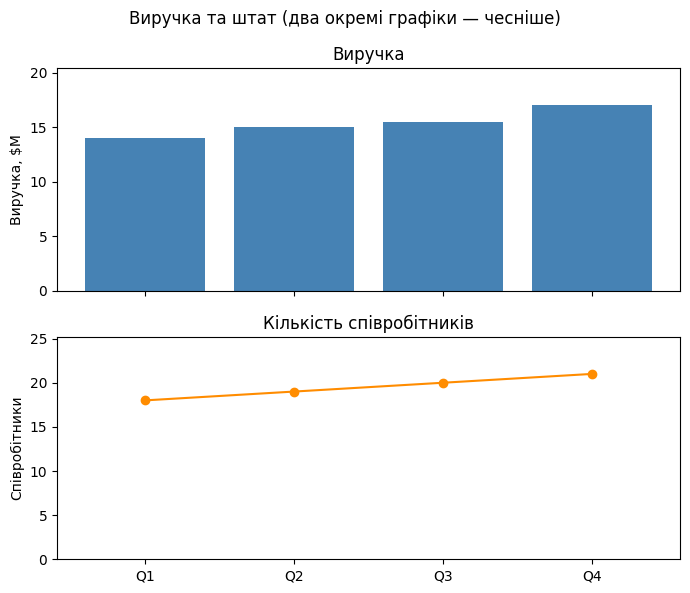

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

axes[0].bar(quarters, revenue, color='steelblue')
axes[0].set_ylabel('Виручка, $M')
axes[0].set_ylim(0, max(revenue) * 1.2)
axes[0].set_title('Виручка')

axes[1].plot(quarters, employees, color='darkorange', marker='o')
axes[1].set_ylabel('Співробітники')
axes[1].set_ylim(0, max(employees) * 1.2)
axes[1].set_title('Кількість співробітників')

fig.suptitle("Виручка та штат (два окремі графіки — чесніше)")
plt.tight_layout()
plt.show()

## Приклади неякісної візуалізації

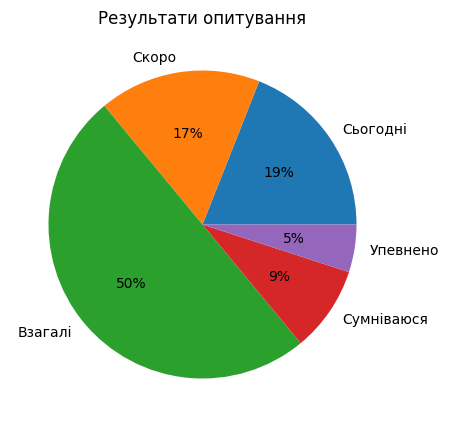

In [9]:
# ---------------------------------------------------------
# 1. Кругова діаграма — "Результати опитування"
# ---------------------------------------------------------
labels = ["Сьогодні", "Скоро", "Взагалі", "Сумніваюся", "Упевнено"]
sizes = [19, 17, 50, 9, 5]

fig1, ax1 = plt.subplots(figsize=(5,5))
ax1.pie(sizes, labels=labels, autopct='%1.0f%%')
ax1.set_title("Результати опитування")
plt.show()

### 🔴 Чому графік неефективний

* Кругові діаграми погано передають різницю між секторами.
* Людське око погано оцінює кути → важко порівнювати значення.
* Багато категорій = текст дрібний.
* Немає чіткого порядку → інтерпретація сповільнюється.

### 🟢 Кращий варіант

**Горизонтальна стовпчикова діаграма**

* Легко порівнювати.
* Можна сортувати.
* Текст читабельний.

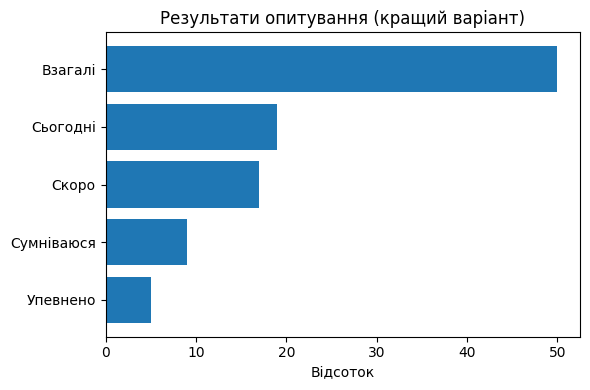

In [10]:
import matplotlib.pyplot as plt

labels = ["Сьогодні", "Скоро", "Взагалі", "Сумніваюся", "Упевнено"]
sizes = [19, 17, 50, 9, 5]

# Сортування для кращої читаємості
sizes_sorted, labels_sorted = zip(*sorted(zip(sizes, labels)))

plt.figure(figsize=(6,4))
plt.barh(labels_sorted, sizes_sorted)
plt.title("Результати опитування (кращий варіант)")
plt.xlabel("Відсоток")
plt.tight_layout()
plt.show()

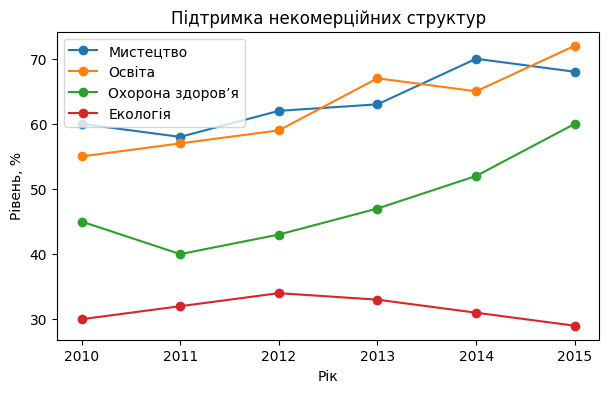

In [11]:
# ---------------------------------------------------------
# 2. Лінійний графік — "Підтримка некомерційних структур"
# ---------------------------------------------------------
years = [2010, 2011, 2012, 2013, 2014, 2015]

arts =      [60, 58, 62, 63, 70, 68]
education = [55, 57, 59, 67, 65, 72]
health =    [45, 40, 43, 47, 52, 60]
environment=[30, 32, 34, 33, 31, 29]

fig2, ax2 = plt.subplots(figsize=(7,4))
ax2.plot(years, arts,        marker="o", label="Мистецтво")
ax2.plot(years, education,   marker="o", label="Освіта")
ax2.plot(years, health,      marker="o", label="Охорона здоров’я")
ax2.plot(years, environment, marker="o", label="Екологія")

ax2.set_title("Підтримка некомерційних структур")
ax2.set_xlabel("Рік")
ax2.set_ylabel("Рівень, %")
ax2.legend()
plt.show()

### 🔴 Чому графік неефективний

* Забагато ліній → втрачається читабельність.
* Легенда громіздка.
* Перетини ліній роблять графік шумним.
* Значення не показані напряму.

### 🟢 Кращий варіант

**Фасет-графік (по одному графіку на категорію)**

* Кожна категорія читається окремо.
* Легко порівнювати тренди.

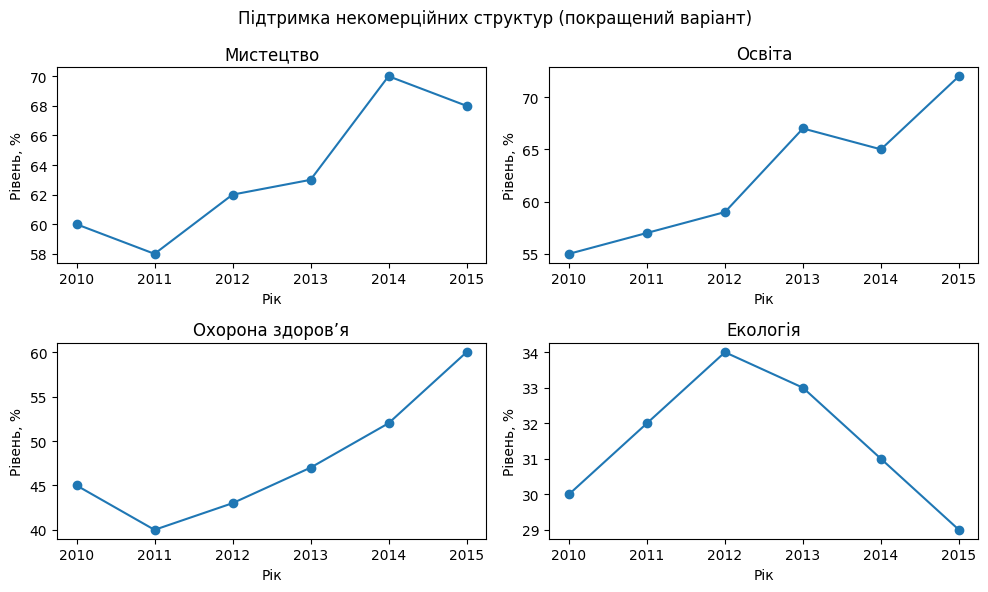

In [12]:
import matplotlib.pyplot as plt

years = [2010, 2011, 2012, 2013, 2014, 2015]
data = {
    "Мистецтво": [60, 58, 62, 63, 70, 68],
    "Освіта": [55, 57, 59, 67, 65, 72],
    "Охорона здоров’я": [45, 40, 43, 47, 52, 60],
    "Екологія": [30, 32, 34, 33, 31, 29]
}

fig, axes = plt.subplots(2, 2, figsize=(10,6))

for ax, (name, values) in zip(axes.flat, data.items()):
    ax.plot(years, values, marker="o")
    ax.set_title(name)
    ax.set_xlabel("Рік")
    ax.set_ylabel("Рівень, %")

fig.suptitle("Підтримка некомерційних структур (покращений варіант)")
plt.tight_layout()
plt.show()

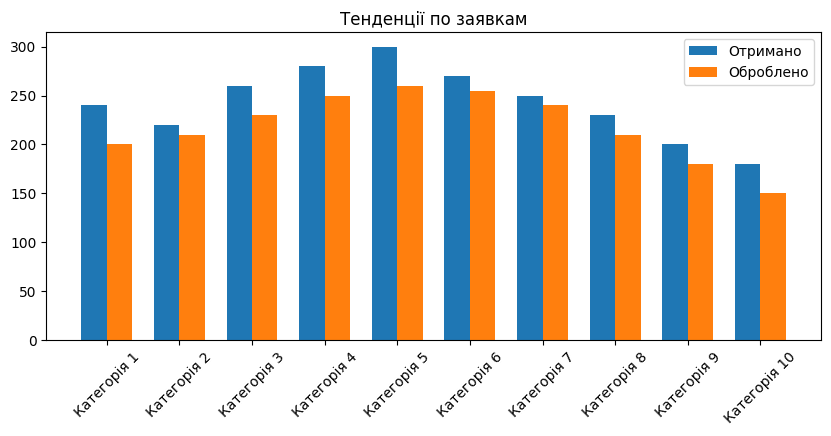

In [13]:
# ---------------------------------------------------------
# 3. Стовпчикова діаграма — "Тенденції по заявленням"
# ---------------------------------------------------------
categories = [f"Категорія {i}" for i in range(1, 11)]
received =   [240, 220, 260, 280, 300, 270, 250, 230, 200, 180]
processed =  [200, 210, 230, 250, 260, 255, 240, 210, 180, 150]

x = np.arange(len(categories))
w = 0.35

fig3, ax3 = plt.subplots(figsize=(10,4))
ax3.bar(x - w/2, received,  width=w, label="Отримано")
ax3.bar(x + w/2, processed, width=w, label="Оброблено")

ax3.set_title("Тенденції по заявкам")
ax3.set_xticks(x)
ax3.set_xticklabels(categories, rotation=45)
ax3.legend()
plt.show()

### 🔴 Чому графік неефективний

* Забагато категорій -> 10 x 2 бари = візуальний шум.
* Важко порівняти різницю між “отримано” і “оброблено”.
* Підписи дрібні та повернуті.

### 🟢 Кращий варіант

**Графік різниці ("отримано − оброблено")**

* Відразу видно відставання обробки.
* Менше шуму, легше інтерпретувати.

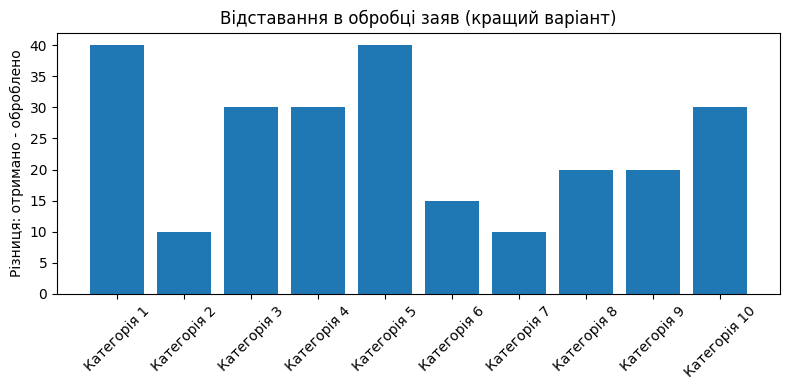

In [14]:
import matplotlib.pyplot as plt
import numpy as np

categories = [f"Категорія {i}" for i in range(1, 11)]
received = np.array([240, 220, 260, 280, 300, 270, 250, 230, 200, 180])
processed = np.array([200, 210, 230, 250, 260, 255, 240, 210, 180, 150])

difference = received - processed

plt.figure(figsize=(8,4))
plt.bar(categories, difference)
plt.title("Відставання в обробці заяв (кращий варіант)")
plt.ylabel("Різниця: отримано - оброблено")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

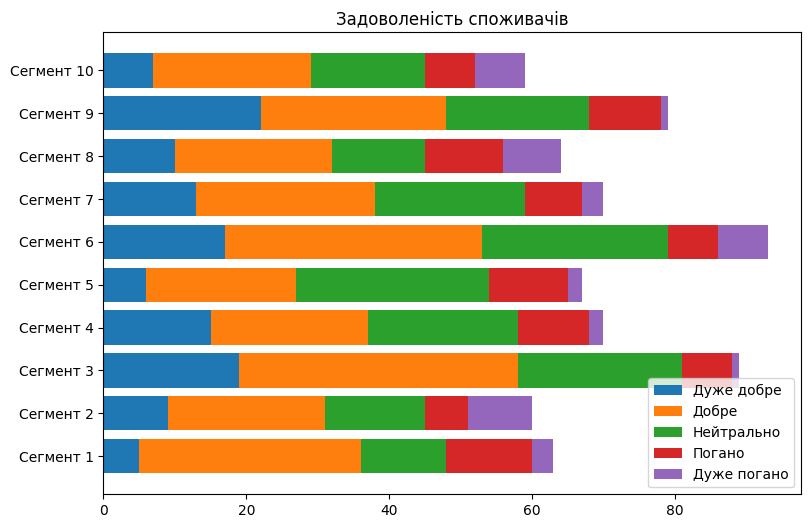

In [15]:
# ---------------------------------------------------------
# 4. Горизонтальні stacked bars — "Задоволеність споживачів"
# ---------------------------------------------------------
segments = [f"Сегмент {i}" for i in range(1, 11)]

very =     np.random.randint(5, 25, 10)
good =     np.random.randint(20, 40, 10)
neutral =  np.random.randint(10, 30, 10)
bad =      np.random.randint(5, 15, 10)
awful =    np.random.randint(1, 10, 10)

fig4, ax4 = plt.subplots(figsize=(9,6))
ax4.barh(segments, very,     label="Дуже добре")
ax4.barh(segments, good,     left=very,     label="Добре")
ax4.barh(segments, neutral,  left=very+good,     label="Нейтрально")
ax4.barh(segments, bad,      left=very+good+neutral,     label="Погано")
ax4.barh(segments, awful,    left=very+good+neutral+bad, label="Дуже погано")

ax4.set_title("Задоволеність споживачів")
ax4.legend(loc="lower right")
plt.show()

### 🔴 Чому графік неефективний

* 10 сегментів × 5 категорій = 50 кольорових блоків.
* Дуже важко прочитати.
* Неможливо відстежити патерни.
* Stacked bars погано порівнюються (крім першої категорії).

### 🟢 Кращий варіант

**Нормалізований stacked bar (100%)**

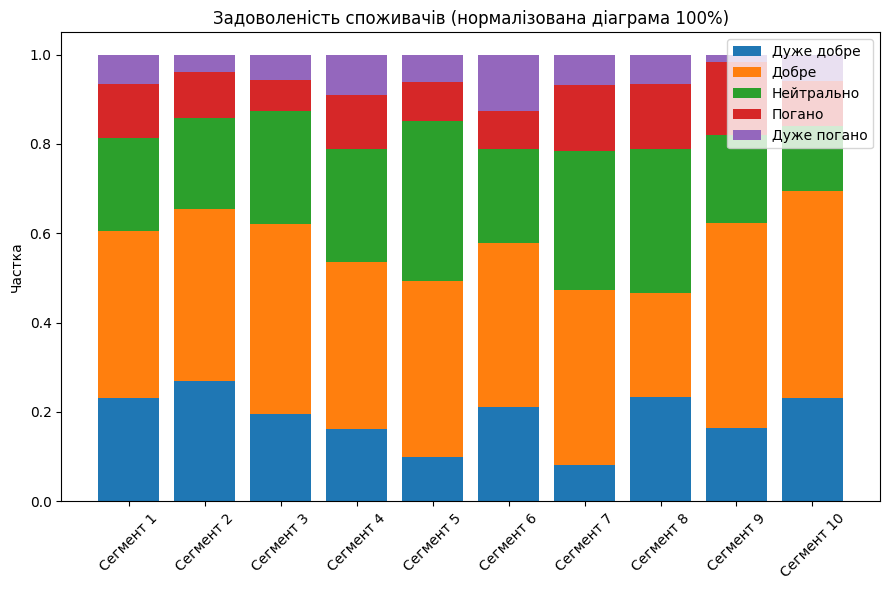

In [16]:
import matplotlib.pyplot as plt
import numpy as np

segments = [f"Сегмент {i}" for i in range(1, 11)]

very =     np.random.randint(5, 25, 10)
good =     np.random.randint(20, 40, 10)
neutral =  np.random.randint(10, 30, 10)
bad =      np.random.randint(5, 15, 10)
awful =    np.random.randint(1, 10, 10)

data = np.vstack([very, good, neutral, bad, awful])

# Нормалізація до 100%
data_pct = data / data.sum(axis=0)

labels = ["Дуже добре", "Добре", "Нейтрально", "Погано", "Дуже погано"]

plt.figure(figsize=(9,6))

bottom = np.zeros(len(segments))

for row, label in zip(data_pct, labels):
    plt.bar(segments, row, bottom=bottom, label=label)
    bottom += row

plt.title("Задоволеність споживачів (нормалізована діаграма 100%)")
plt.ylabel("Частка")
plt.xticks(rotation=45)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

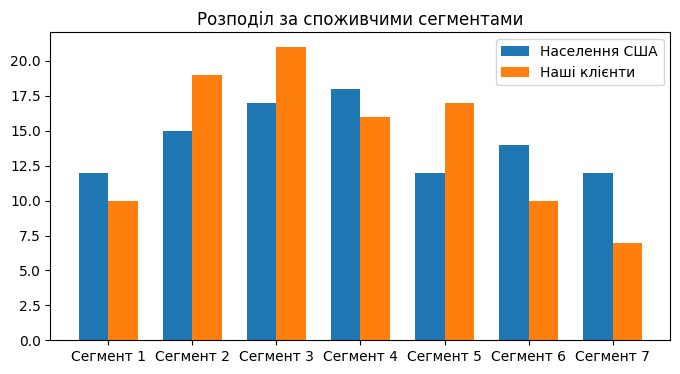

In [17]:
# ---------------------------------------------------------
# 5. Дві стовпчикові серії — "Розподіл за споживчими сегментами"
# ---------------------------------------------------------
segments = [f"Сегмент {i}" for i in range(1, 8)]
us_pop =    [12, 15, 17, 18, 12, 14, 12]
our_clients=[10, 19, 21, 16, 17, 10, 7]

x = np.arange(len(segments))
w = 0.35

fig5, ax5 = plt.subplots(figsize=(8,4))
ax5.bar(x - w/2, us_pop, width=w, label="Населення США")
ax5.bar(x + w/2, our_clients, width=w, label="Наші клієнти")

ax5.set_title("Розподіл за споживчими сегментами")
ax5.set_xticks(x)
ax5.set_xticklabels(segments)
ax5.legend()
plt.show()

### 🔴 Чому графік неефективний

* Side-by-side bars для 7 категорій → важко читати.
* Маленькі відмінності зникають.
* Важко помітити пропорції.

### 🟢 Кращий варіант

**Лінійний графік / або різниця між групами**

Показ різниці → дає інсайт миттєво.

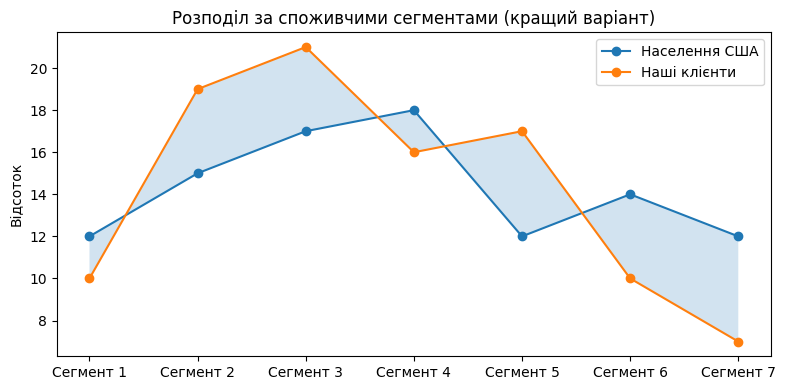

In [18]:
import matplotlib.pyplot as plt
import numpy as np

segments = [f"Сегмент {i}" for i in range(1, 8)]
us = np.array([12, 15, 17, 18, 12, 14, 12])
clients = np.array([10, 19, 21, 16, 17, 10, 7])

diff = clients - us

plt.figure(figsize=(8,4))
plt.plot(segments, us, marker='o', label="Населення США")
plt.plot(segments, clients, marker='o', label="Наші клієнти")
plt.fill_between(segments, us, clients, alpha=0.2)

plt.title("Розподіл за споживчими сегментами (кращий варіант)")
plt.ylabel("Відсоток")
plt.legend()
plt.tight_layout()
plt.show()

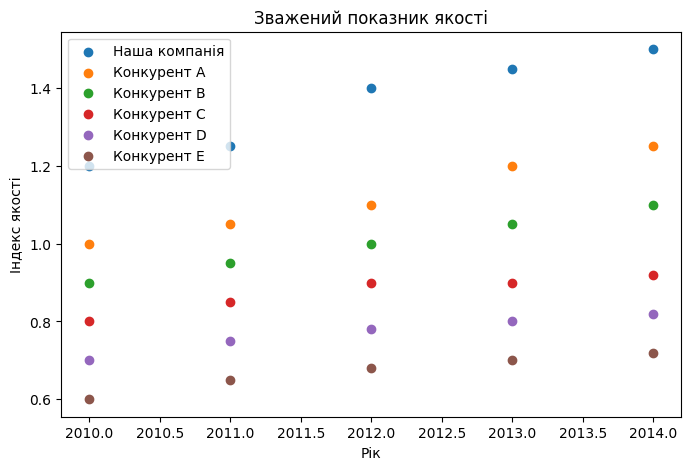

In [19]:
# ---------------------------------------------------------
# 6. Діаграма з точками — "Зважений показник якості"
# ---------------------------------------------------------
years = [2010, 2011, 2012, 2013, 2014]

competitors = {
    "Наша компанія": [1.2, 1.25, 1.4, 1.45, 1.5],
    "Конкурент A":   [1.0, 1.05, 1.1, 1.2, 1.25],
    "Конкурент B":   [0.9, 0.95, 1.0, 1.05, 1.1],
    "Конкурент C":   [0.8, 0.85, 0.9, 0.9, 0.92],
    "Конкурент D":   [0.7, 0.75, 0.78, 0.8, 0.82],
    "Конкурент E":   [0.6, 0.65, 0.68, 0.7, 0.72],
}

fig6, ax6 = plt.subplots(figsize=(8,5))

for name, values in competitors.items():
    ax6.scatter(years, values, label=name)

ax6.set_title("Зважений показник якості")
ax6.set_xlabel("Рік")
ax6.set_ylabel("Індекс якості")
ax6.legend()
plt.show()

### 🔴 Чому графік неефективний

* 6 конкурентів × 5 років → хаос.
* Кольори подібні.
* Точки без ліній → важко побачити тренд.
* Немає структури.

### 🟢 Кращий варіант

**Лінійний графік у фасетах (один конкурент = один маленький графік)**

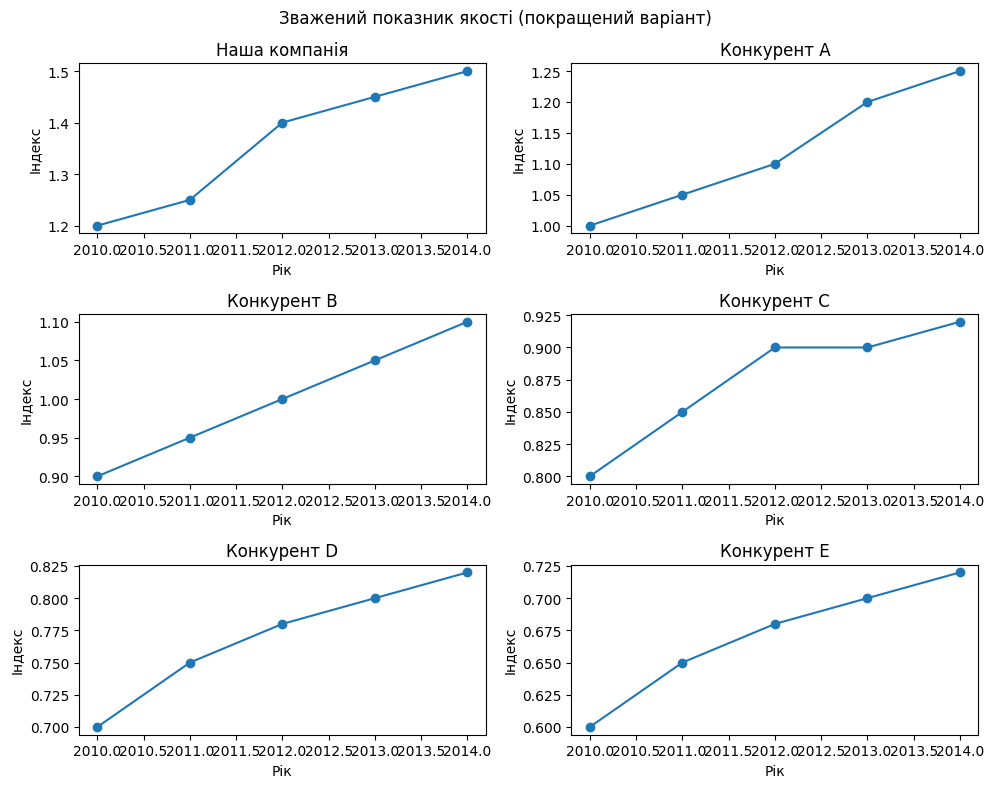

In [20]:
import matplotlib.pyplot as plt

years = [2010, 2011, 2012, 2013, 2014]
competitors = {
    "Наша компанія": [1.2, 1.25, 1.4, 1.45, 1.5],
    "Конкурент A":   [1.0, 1.05, 1.1, 1.2, 1.25],
    "Конкурент B":   [0.9, 0.95, 1.0, 1.05, 1.1],
    "Конкурент C":   [0.8, 0.85, 0.9, 0.9, 0.92],
    "Конкурент D":   [0.7, 0.75, 0.78, 0.8, 0.82],
    "Конкурент E":   [0.6, 0.65, 0.68, 0.7, 0.72],
}

fig, axes = plt.subplots(3, 2, figsize=(10,8))

for ax, (name, values) in zip(axes.flat, competitors.items()):
    ax.plot(years, values, marker="o")
    ax.set_title(name)
    ax.set_xlabel("Рік")
    ax.set_ylabel("Індекс")

fig.suptitle("Зважений показник якості (покращений варіант)")
plt.tight_layout()
plt.show()

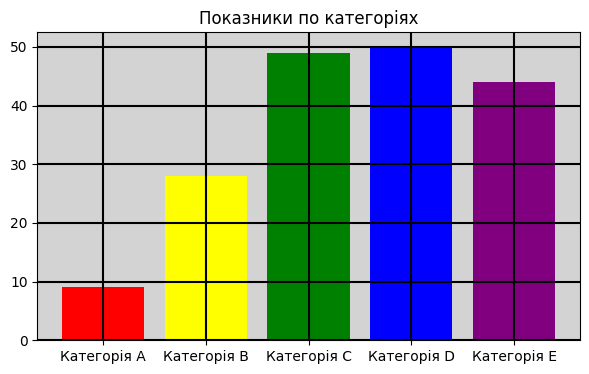

In [21]:
# ---------------------------------------------------------
# 7. "Радужний" барчарт без сенсу в кольорі
# ---------------------------------------------------------
categories = ["Категорія A", "Категорія B", "Категорія C", "Категорія D", "Категорія E"]
values = [9, 28, 49, 50, 44]

plt.figure(figsize=(7, 4))
plt.bar(categories, values, color=['red', 'yellow', 'green', 'blue', 'purple'])
plt.gca().set_facecolor('lightgray')
plt.grid(True, color='black', linewidth=1.5)
plt.title("Показники по категоріях")
plt.show()

### 🔴 Чому графік неефективний

* Кожна категорія — свій колір із "радужної" палітри, хоча категорії рівнозначні й колір нічого не означає (не кодує ні групу, ні порядок, ні значення).
* Коли виділено все одразу — не виділено нічого: око не знає, на що дивитись першим.
* Сірий фон і жирна чорна сітка — зайвий візуальний шум, який не несе інформації, але забирає увагу.

### 🟢 Кращий варіант

**Один нейтральний колір для всіх категорій + акцент тільки на головній.** Якщо потрібно привернути увагу до конкретного значення (наприклад, найбільшого) — виділяємо яскравим кольором лише його, решту залишаємо сірими.

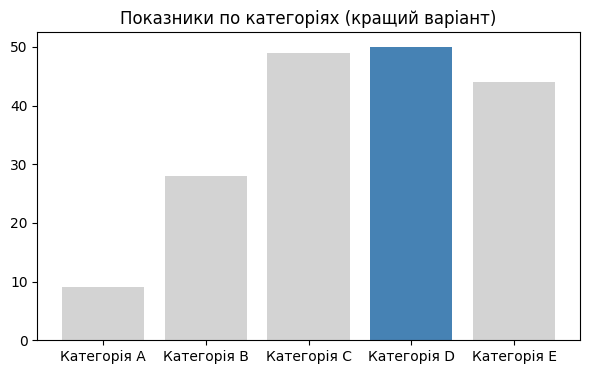

In [22]:
categories = ["Категорія A", "Категорія B", "Категорія C", "Категорія D", "Категорія E"]
values = [9, 28, 49, 50, 44]

colors = ['lightgray'] * len(categories)
colors[values.index(max(values))] = 'steelblue'  # акцент лише на максимумі

plt.figure(figsize=(7, 4))
plt.bar(categories, values, color=colors)
plt.title("Показники по категоріях (кращий варіант)")
plt.show()

## Бібліотеки

**Seaborn**

* Побудований на основі matplotlib.
* Простий синтаксис для статистичних графіків.
* Добре підходить для дослідницького аналізу (EDA).

**Plotly**

* Інтерактивні графіки.
* Підходить для презентацій, дашбордів.
* Можна наводити, збільшувати, клікати.

In [23]:
!pip install seaborn

In [24]:
!pip install plotly

In [25]:
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

Далі розглянемо 5 основних типів графіків на тому самому датасеті будинків (`df`). Для кожного — спочатку теорія, потім **як не варто** робити, і одразу поруч — **як краще**.

## Гістограма

**Гістограма (histogram)** показує **розподіл однієї кількісної змінної**: як часто зустрічаються значення в різних діапазонах ("бінах"). Відповідає на питання "як виглядає розподіл?" — чи симетричний, чи скошений, де концентрація значень, чи є кілька "горбів" (мод).

Головний параметр, яким легко зіпсувати гістограму, — **кількість бінів (`bins`)**:

* Замало бінів → втрачаються деталі форми розподілу, все виглядає як 2-3 прямокутники.
* Забагато бінів → графік перетворюється на шум із тисяч тонких стовпчиків, форму розподілу не видно.

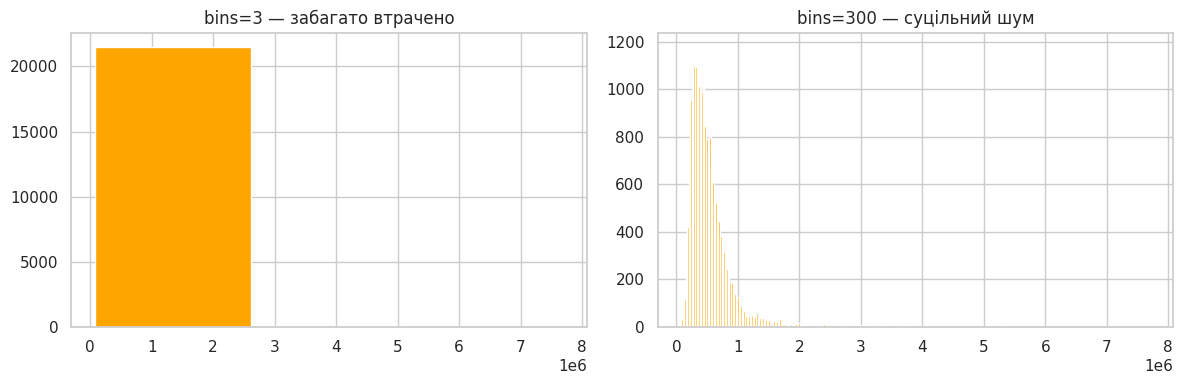

In [26]:
# 🔴 ЯК НЕ ВАРТО: замало бінів і забагато бінів — обидва варіанти ховають форму розподілу
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['price'], bins=3, color='orange')
axes[0].set_title("bins=3 — забагато втрачено")

axes[1].hist(df['price'], bins=300, color='orange')
axes[1].set_title("bins=300 — суцільний шум")

plt.tight_layout()
plt.show()

### 🔴 Чому графіки неефективні

* `bins=3`: усі 21613 будинків стиснуті в 3 стовпчики — видно лише "більшість дешева", і все. Форма розподілу (скошеність, викиди) зникла.
* `bins=300`: занадто детально — кожен стовпчик описує вузький ціновий діапазон з малою кількістю будинків, графік перетворюється на зубчастий шум, у якому не видно загальної форми.
* Жоден з двох варіантів навіть не натякає, що `price` сильно скошена праворуч (є невелика кількість дуже дорогих будинків) — а це критично важливий факт про дані (ми це вже бачили в лекції 17 через `skew()` і `log(price)`).

### 🟢 Кращий варіант

Розумна кількість бінів (не бездумно "за замовчуванням", а підібрана під об'єм даних) **плюс** лог-трансформація для сильно скошеної величини — так само, як ми вже робили для `price` в лекції про довірчі інтервали.

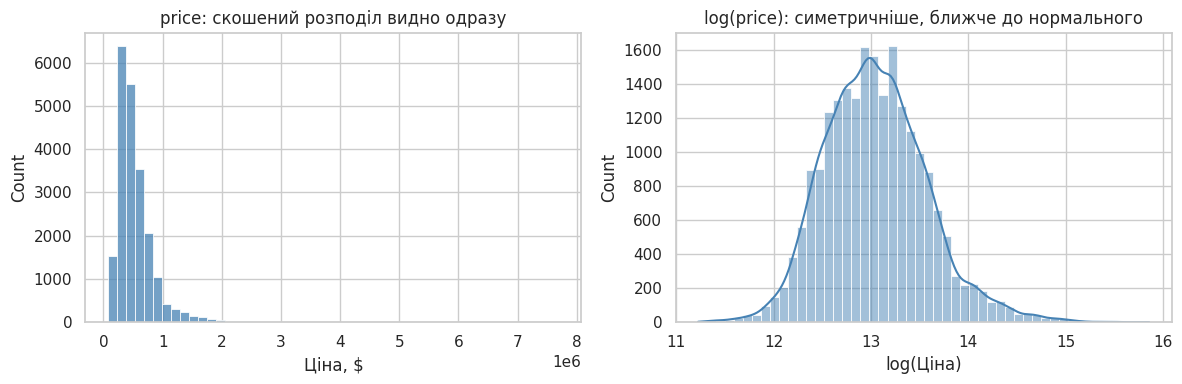

In [27]:
# 🟢 ЯК КРАЩЕ: адекватна кількість бінів + лог-трансформація для скошеної ціни
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['price'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title("price: скошений розподіл видно одразу")
axes[0].set_xlabel("Ціна, $")

sns.histplot(np.log(df['price']), bins=50, ax=axes[1], color='steelblue', kde=True)
axes[1].set_title("log(price): симетричніше, ближче до нормального")
axes[1].set_xlabel("log(Ціна)")

plt.tight_layout()
plt.show()

**Висновок:** на лівій гістограмі (50 бінів) видно те, чого не було на попередніх двох — довгий "хвіст" дорогих будинків. На правій (у лог-масштабі) розподіл симетричніший, що й пояснює, чому в лекції 17 для довірчого інтервалу середньої ціни ми працювали саме з `log(price)`.

## Boxplot (ящик з вусами)

**Boxplot** показує розподіл кількісної змінної через 5 чисел: мінімум/максимум "в межах вусів", межі коробки (25-й і 75-й перцентиль, тобто IQR), медіану (лінія всередині коробки) і окремі точки-викиди. Головна сила boxplot — **порівняння розподілу між кількома групами на одному графіку**.

Типова помилка — будувати boxplot по категоріальній змінній із **забагато унікальних значень**: графік перетворюється на невпорядкований ряд вузьких коробочок, порівнювати які майже неможливо.

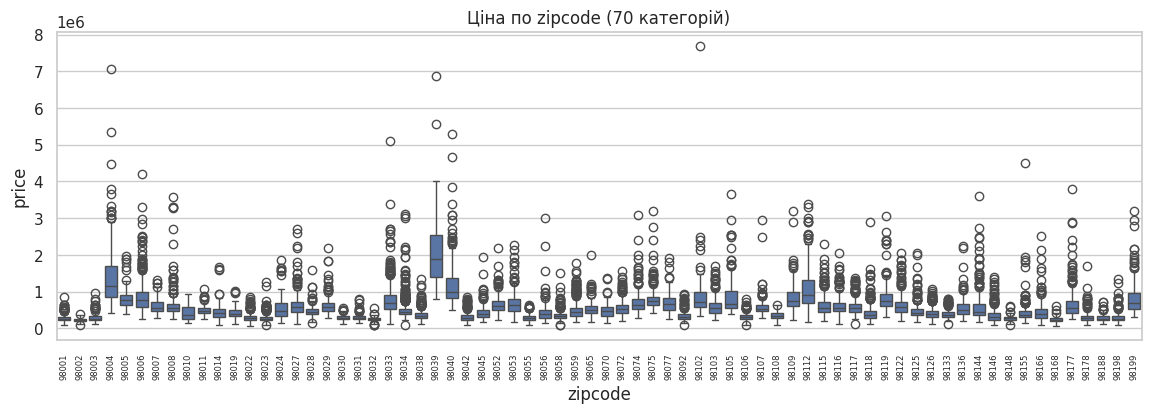

In [28]:
# 🔴 ЯК НЕ ВАРТО: boxplot по zipcode — 70 унікальних поштових індексів в довільному порядку
plt.figure(figsize=(14, 4))
sns.boxplot(data=df, x='zipcode', y='price')
plt.xticks(rotation=90, fontsize=6)
plt.title("Ціна по zipcode (70 категорій)")
plt.show()

### 🔴 Чому графік неефективний

* 70 коробочок підряд — підписи осі X зливаються, читати неможливо навіть зменшивши шрифт.
* Порядок — це просто числовий порядок індексів, він нічого не каже про ціну; найдорожчі й найдешевші райони розкидані по всій ширині графіка.
* Викиди (точки) накладаються одна на одну, їх неможливо відрізнити від "нормальних" значень суміжних груп.

### 🟢 Кращий варіант

Взяти змінну з невеликою кількістю природних категорій (`bedrooms`) і **відсортувати групи за медіаною**, щоб тенденція була видна одразу, а не вгадувалась.

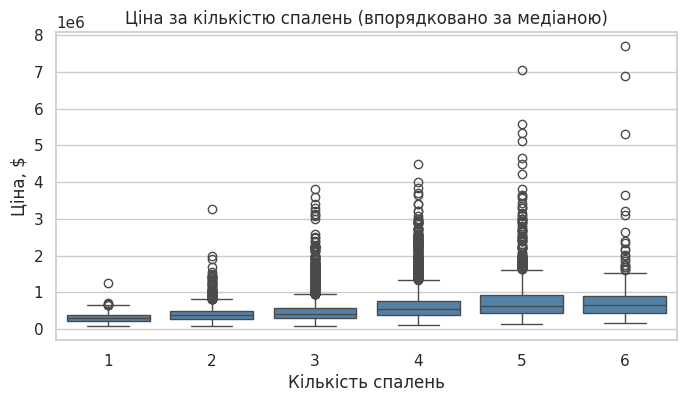

In [29]:
# 🟢 ЯК КРАЩЕ: невелика кількість категорій, впорядкованих за медіаною
subset = df[df['bedrooms'].between(1, 6)]  # прибираємо рідкісні 0, 7+ спальень — окремі викиди

order = subset.groupby('bedrooms')['price'].median().sort_values().index

plt.figure(figsize=(8, 4))
sns.boxplot(data=subset, x='bedrooms', y='price', order=order, color='steelblue')
plt.title("Ціна за кількістю спалень (впорядковано за медіаною)")
plt.xlabel("Кількість спалень")
plt.ylabel("Ціна, $")
plt.show()

**Висновок:** тепер коробочки йдуть за зростанням медіани зліва праворуч — тенденцію "більше спалень → вища ціна" видно одним погляд, без необхідності подумки сортувати 70 підписів.

## Scatterplot (діаграма розсіювання)

**Scatterplot** показує зв'язок між **двома кількісними змінними** — кожна точка це один спостереження. Саме цей графік ми фактично "рахували числом" через кореляцію Пірсона/Спірмена в лекції 17 — scatterplot дозволяє побачити форму зв'язку (лінійний? нелінійний? є викиди?), яку одне число кореляції не покаже.

Типова проблема при великій кількості спостережень — **overplotting**: тисячі точок накладаються одна на одну, і стає не видно, де насправді щільність висока.

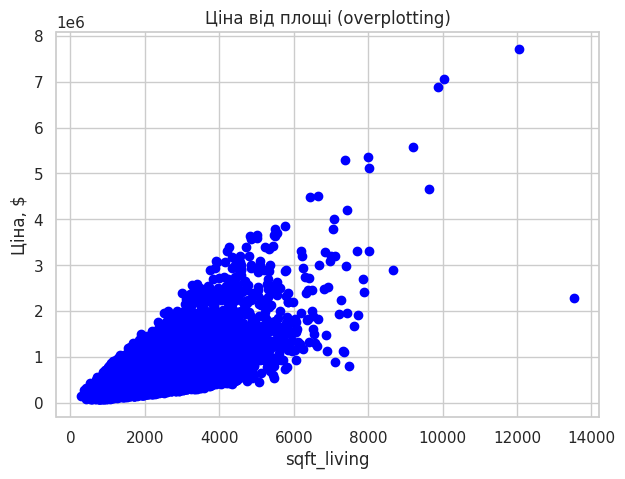

In [30]:
# 🔴 ЯК НЕ ВАРТО: 21613 суцільних точок без прозорості — злипаються в одну темну масу
plt.figure(figsize=(7, 5))
plt.scatter(df['sqft_living'], df['price'], color='blue')
plt.title("Ціна від площі (overplotting)")
plt.xlabel("sqft_living")
plt.ylabel("Ціна, $")
plt.show()

### 🔴 Чому графік неефективний

* Велика щільність точок у нижньому лівому куті зливається в суцільну темну плюму — неможливо сказати, де насправді концентрація найбільша: у 1000 точках чи в 10000.
* Непрозорі (`alpha=1`) точки одного кольору не дають жодної додаткової інформації про інші характеристики будинків.
* Кілька екстремальних викидів (дуже дорогі будинки) розтягують вісь Y так, що основна маса точок стискається в нижній частині графіка.

### 🟢 Кращий варіант

Додати **прозорість (`alpha`)**, щоб щільність точок була видна через накладання, і **колір, що кодує змістовну третю змінну** (`grade` — якість будівництва) замість суцільного кольору без сенсу.

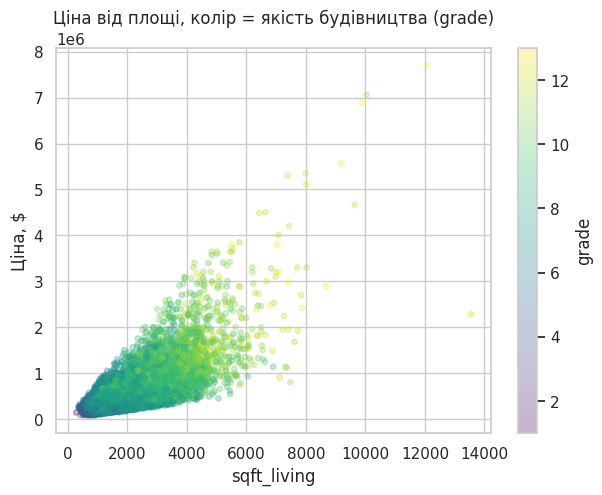

In [31]:
# 🟢 ЯК КРАЩЕ: прозорість проти overplotting + колір кодує grade (а не "просто для краси")
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(
    df['sqft_living'], df['price'],
    c=df['grade'], cmap='viridis', alpha=0.3, s=15
)
ax.set_title("Ціна від площі, колір = якість будівництва (grade)")
ax.set_xlabel("sqft_living")
ax.set_ylabel("Ціна, $")
plt.colorbar(scatter, label='grade')
plt.show()

**Висновок:** прозорість одразу показує, де насправді найбільша концентрація будинків (темніші ділянки — там, де точки накладаються найщільніше), а послідовна (не "радужна") палітра `viridis`, прив'язана до реальної змінної `grade`, пояснює частину розкиду цін: при однаковій площі будинки з вищим `grade` систематично дорожчі.

## Barplot (стовпчикова діаграма + агрегація)

На відміну від гістограми (яка рахує, скільки спостережень потрапило в кожен діапазон однієї змінної), **barplot з агрегацією** показує **одне підсумкове число** (середнє, медіану, суму) **для кожної категорії** іншої змінної. Це саме той випадок, де легко сплутати середнє з медіаною (ми це розбирали в лекції 17): якщо розподіл всередині групи скошений, середнє і медіана можуть суттєво відрізнятись і дати різну картину "типової" ціни.

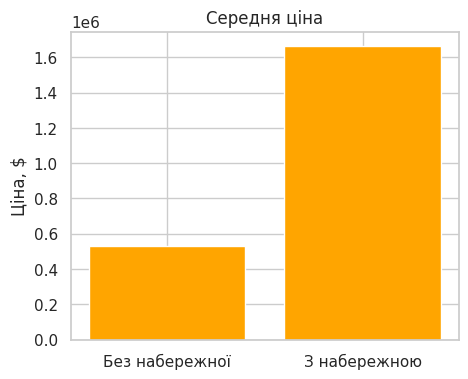

In [32]:
# 🔴 ЯК НЕ ВАРТО: середнє по скошеній величині без жодної згадки про розкид чи альтернативу
mean_by_waterfront = df.groupby('waterfront')['price'].mean()

plt.figure(figsize=(5, 4))
plt.bar(['Без набережної', 'З набережною'], mean_by_waterfront.values, color='orange')
plt.title("Середня ціна")
plt.ylabel("Ціна, $")
plt.show()

### 🔴 Чому графік неефективний

* Показано тільке середнє, без жодного зазначення, наскільки воно надійне (немає error bar / довірчого інтервалу) — графік виглядає як точний факт, хоча це оцінка по вибірці.
* Середнє в групі "з набережною" сильно тягнеться вгору кількома дуже дорогими будинками (ми бачили в домашньому завданні про `waterfront`, що там є екстремальні ціни) — не ясно, чи це "типовий" будинок з набережною, чи ефект кількох викидів.
* Немає підпису кількості будинків у кожній групі (`n`), хоча групи дуже різні за розміром (163 проти 21450) — це критична відмінність, яку варто показувати поруч.

### 🟢 Кращий варіант

Показати і середнє, і медіану поруч (щоб було видно розбіжність від скошеності), додати довірчий інтервал середнього (`seaborn` робить це автоматично через error bar) і підписати розмір вибірки.

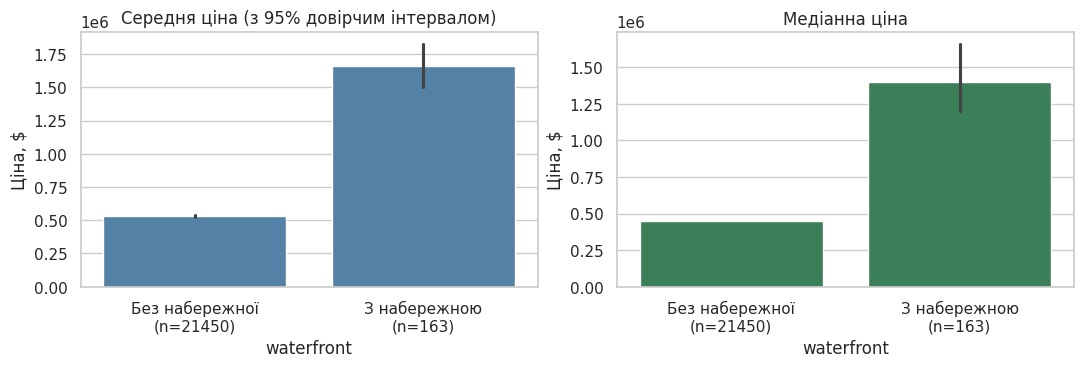

In [33]:
# 🟢 ЯК КРАЩЕ: середнє з довірчим інтервалом (error bar) + медіана поруч + розмір групи
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=df, x='waterfront', y='price', estimator=np.mean, errorbar=('ci', 95), ax=axes[0], color='steelblue')
axes[0].set_xticklabels(['Без набережної\n(n=21450)', 'З набережною\n(n=163)'])
axes[0].set_title("Середня ціна (з 95% довірчим інтервалом)")
axes[0].set_ylabel("Ціна, $")

sns.barplot(data=df, x='waterfront', y='price', estimator=np.median, ax=axes[1], color='seagreen')
axes[1].set_xticklabels(['Без набережної\n(n=21450)', 'З набережною\n(n=163)'])
axes[1].set_title("Медіанна ціна")
axes[1].set_ylabel("Ціна, $")

plt.tight_layout()
plt.show()

**Висновок:** тонкі чорні "вусики" на лівому графіку — це 95% довірчий інтервал середнього: для групи "з набережною" він помітно ширший (бо n=163 проти n=21450), тобто середнє в маленькій групі оцінене менш точно. Порівняння з медіаною праворуч показує, що різниця між групами реальна й не є лише артефактом кількох дорогих викидів — хоча саме числове співвідношення середнього й медіани в кожній групі варто завжди перевіряти, а не припускати.

## Lineplot (лінійний графік)

**Lineplot** — стандартний вибір для даних, впорядкованих по осі X, найчастіше за часом: показує тренд, а не окремі спостереження. Ключова помилка — будувати лінію по **занадто "сирих" (не агрегованих) даних**: щоденні коливання маскують справжній тренд шумом, так само як ми вже бачили з `resample()` в лекції 20 — тільки тут проблема в тому, що її не видно на око, поки не намалюєш.

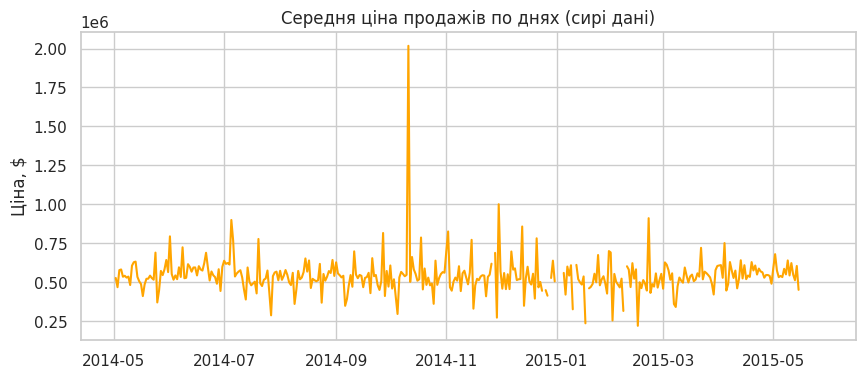

In [34]:
# 🔴 ЯК НЕ ВАРТО: середня ціна по кожному дню окремо — забагато шуму, тренд не видно
daily = df.set_index('date')['price'].resample('D').mean()

plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily.values, color='orange')
plt.title("Середня ціна продажів по днях (сирі дані)")
plt.ylabel("Ціна, $")
plt.show()

### 🔴 Чому графік неефективний

* У деякі дні продано лише кілька будинків — їхнє середнє дуже нестабільне (випадковий дорогий будинок одразу підкидає денне "середнє" до $2 млн+), тому лінія виглядає як хаотичні зубці.
* Справжній тренд цін (якщо він є) повністю ховається за цим шумом вибірки малого розміру.
* Графік створює враження різких "стрибків" ціни на ринку день у день, яких насправді немає — це вже спотворення, схоже на обрізану вісь Y чи зміну масштабу з початку лекції.

### 🟢 Кращий варіант

Агрегувати до **місяця** (`resample('ME')`, як у лекції 20) — у кожному місяці достатньо продажів, щоб середнє було стабільним, і справжній тренд (якщо він є) стане видно.

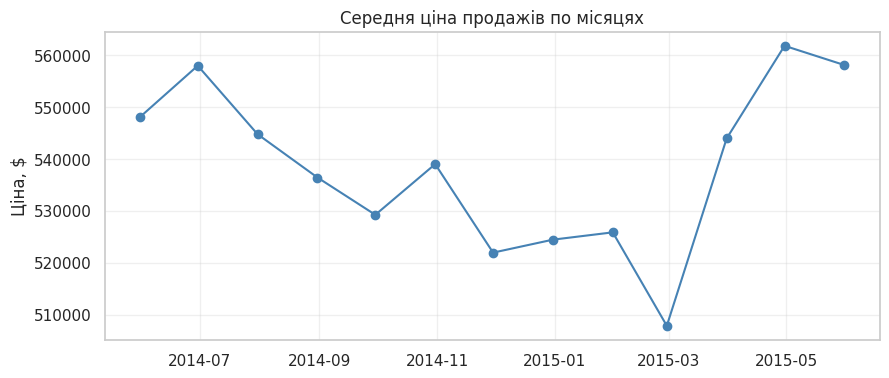

In [35]:
# 🟢 ЯК КРАЩЕ: агрегація по місяцю замість по дню — тренд видно, шум прибраний
monthly = df.set_index('date')['price'].resample('ME').mean()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker='o', color='steelblue')
plt.title("Середня ціна продажів по місяцях")
plt.ylabel("Ціна, $")
plt.grid(True, alpha=0.3)
plt.show()

**Висновок:** після агрегації по місяцю лінія стала набагато гладшою — кожна точка тепер спирається на 600–2200 продажів замість кількох десятків на день, тому хаотичні "зубці" зникли і видно реальну динаміку: спад середньої ціни до лютого 2015 і подальше відновлення, а не випадкові стрибки через малу вибірку. Правило просте: чим менше спостережень припадає на одну точку лінії, тим менше можна довіряти цій точці — перед тим як малювати лінійний графік, варто перевірити, скільком спостереженням відповідає кожна точка (`.resample().count()`).

## Підсумок: що коли використовувати

| Тип графіка | Що показує | Головна пастка |
| --- | --- | --- |
| Гістограма | Розподіл **однієї** кількісної змінної | Невдала кількість бінів (замало/забагато) ховає форму розподілу |
| Boxplot | Порівняння розподілу **між групами** (медіана, IQR, викиди) | Забагато категорій без сортування — порівнювати неможливо |
| Scatterplot | Зв'язок між **двома** кількісними змінними | Overplotting: тисячі точок без прозорості зливаються в суцільну масу |
| Barplot (з агрегацією) | Одне підсумкове число (середнє/медіана) **для кожної категорії** | Показане тільки середнє без довірчого інтервалу й без урахування розміру груп |
| Lineplot | Тренд **упорядкованої** величини (найчастіше — часу) | Занадто "сирі" (не агреговані) дані — шум ховає справжній тренд |

І наскрізне правило з початку лекції: **колір, масштаб осей і тип графіка завжди повинні обиратись так, щоб точно передати дані, а не так, щоб графік "виглядав ефектніше".**